## PROYECTO FINAL - CURSO "FUNDAMENTOS DE DATA SCIENCES"
https://www.kaggle.com/datasets/huseyinelci/wne-qualty-by-uci
https://archive.ics.uci.edu/dataset/186/wine+quality

#### **IMPORTAMOS LIBRERIAS**

In [43]:
# Importamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### **CARGAMOS DATASET**

In [44]:
# Cargo dataset
wq_df = pd.read_csv('csv/WineQuality-RedWine.csv',delimiter=',')
wq_df.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


#### **INSPECCIONAMOS LOS DATOS**

Para conocer un poco más de nuestro dataset, responderemos las siguientes preguntas:

1. **¿Cuantás columnas y filas posee el dataset?**
2. **¿Cuales son los nombre de nuestras columnas?**
3. **¿Existen valores faltantes? y duplicados?**

In [45]:
# Respondiendo la primer pregunta
print(f"Columnas:{wq_df.shape[0]} | Filas:{wq_df.shape[1]}")

Columnas:1599 | Filas:12


In [46]:
# Respondiendo la segunda pregunta
print(f"El nombre de las columnas son:\n{wq_df.columns}")

El nombre de las columnas son:
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')


Puedo observar que existen espacios entre cada palabra por lo que voy a proceder a **'renombrar las columnas'** eliminando los espacios y asignando un nombre mas facil de comprender,

In [47]:
# Creo un diccionario con los nombre de las columnas.
renombre_columnas = {
    'fixed acidity':'acidez_fija',
    'volatile acidity':'acidez_volatil',
    'citric acid':'acido_citrico',
    'residual sugar':'azucar_residual',
    'chlorides':'cloruros',
    'free sulfur dioxide':'dioxido_azufre_libre',
    'total sulfur dioxide':'dioxido_azufre_total',
    'density':'densidad',
    'pH':'PH',
    'sulphates':'sulfatos',
    'alcohol':'alcohol',
    'quality':'calidad'
}

wq_df = wq_df.rename(renombre_columnas,axis='columns')
wq_df

,acidez_fija,acidez_volatil,acido_citrico,azucar_residual,cloruros,dioxido_azufre_libre,dioxido_azufre_total,densidad,PH,sulfatos,alcohol,calidad
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


Continuamos con la exploración de nuestros datos...

In [48]:
wq_df.describe()

,acidez_fija,acidez_volatil,acido_citrico,azucar_residual,cloruros,dioxido_azufre_libre,dioxido_azufre_total,densidad,PH,sulfatos,alcohol,calidad
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


Tendríamos que ver luego, si los rangos (max,min) para cada uno de las características de un vino tipico, son acordes o deberíamos escalar.

In [49]:
wq_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   acidez_fija           1599 non-null   float64
 1   acidez_volatil        1599 non-null   float64
 2   acido_citrico         1599 non-null   float64
 3   azucar_residual       1599 non-null   float64
 4   cloruros              1599 non-null   float64
 5   dioxido_azufre_libre  1599 non-null   float64
 6   dioxido_azufre_total  1599 non-null   float64
 7   densidad              1599 non-null   float64
 8   PH                    1599 non-null   float64
 9   sulfatos              1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  calidad               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


Como puede observarse del info(), no tenemos datos faltantes... pero haremos una breve exploración de los mismos.

#### **DATOS FALTANTES**

In [50]:
# Realizo la suma de valores faltantes, si los hubiera, sobre cada una de las columnas.
wq_df.isna().sum(axis=0)

acidez_fija             0
acidez_volatil          0
acido_citrico           0
azucar_residual         0
cloruros                0
dioxido_azufre_libre    0
dioxido_azufre_total    0
densidad                0
PH                      0
sulfatos                0
alcohol                 0
calidad                 0
dtype: int64

Veamos si hay **valores duplicados**... De haberlos, debería eliminarlos para que no afecten al modelo luego.

In [51]:
print(f"La cantidad de duplicados es: {wq_df.duplicated().sum()}")

La cantidad de duplicados es: 240


In [52]:
# Realizo una copia del dataframe
wq_df_copy = wq_df.copy()
#Elimino los duplicados
wq_df = wq_df.drop_duplicates()

In [53]:
#Chequeo cuantas filas me quedaron luego de la eliminación
print(f"Luego de la eliminación de duplicados, me quedan {wq_df.shape[0]} filas.")

Luego de la eliminación de duplicados, me quedan 1359 filas.


#### **FILTRADO DE DATOS**

🤔 &nbsp; **¿Cuantos datos unicos posee la feacture 'calidad'?**

In [54]:
wq_df['calidad'].unique()

array([5, 6, 7, 4, 8, 3])

🤔 &nbsp; **¿Cuantos vinos poseen una calidad mayor a seis?**

In [55]:
# Creo una mascara booleana
vinos_mascara = wq_df['calidad'] >= 6
wq_df[vinos_mascara]

,acidez_fija,acidez_volatil,acido_citrico,azucar_residual,cloruros,dioxido_azufre_libre,dioxido_azufre_total,densidad,PH,sulfatos,alcohol,calidad
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
7,7.3,0.65,0.00,1.2,0.065,15.0,21.0,0.99460,3.39,0.47,10.0,7
8,7.8,0.58,0.02,2.0,0.073,9.0,18.0,0.99680,3.36,0.57,9.5,7
16,8.5,0.28,0.56,1.8,0.092,35.0,103.0,0.99690,3.30,0.75,10.5,7
19,7.9,0.32,0.51,1.8,0.341,17.0,56.0,0.99690,3.04,1.08,9.2,6
...,...,...,...,...,...,...,...,...,...,...,...,...
1591,5.4,0.74,0.09,1.7,0.089,16.0,26.0,0.99402,3.67,0.56,11.6,6
1592,6.3,0.51,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1593,6.8,0.62,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
1595,5.9,0.55,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6


En enología, no existe un valor único perfecto, ya que los parámetros ideales cambian según el estilo (tinto, blanco, espumante o dulce), pero los indicadores clave de un vino sano y bien elaborado son:
 * **Grado alcohólico**: Suele situarse entre 11,5 % y 15 % en vinos tranquilos
 * **pH**: El pH ideal oscila entre 3,0 y 3,8.
 * **Azúcares residuales**: En vinos secos deben ser bajos (generalmente menos de 2 a 4 g/L).
 * **Anhídrido sulfuroso (SO₂)**: Protege contra la oxidación y las bacterias. Un buen manejo enológico busca niveles de SO₂ libre suficientes (usualmente entre 20 y 40 mg/L) para cuidar el vino sin que se perciba un olor picante o a fósforo.
 * **Acidez volátil (ácido acético)**: Indica inicio de avinagramiento. En vinos sanos suele estar por debajo de 0,6 - 0,8 g/L.

 Bajo estas condiciones me surgue la siguiente pregunta: **¿Cual es la calidad numérica bajo estas condiciones?**

In [56]:
# Mascaras
m_alcohol = (wq_df['alcohol'] > 11.5) & (wq_df['alcohol'] < 15)
m_ph = (wq_df['PH'] > 3.00) & (wq_df['PH'] < 3.8)
m_azucares = (wq_df['PH'] < 4)
m_sulfuros = (wq_df['dioxido_azufre_libre'] > 20) & (wq_df['dioxido_azufre_libre'] < 40)
m_acidez = (wq_df['acidez_volatil'] < 0.8)

wq_df[(m_alcohol & m_ph & m_azucares & m_sulfuros & m_acidez)]

,acidez_fija,acidez_volatil,acido_citrico,azucar_residual,cloruros,dioxido_azufre_libre,dioxido_azufre_total,densidad,PH,sulfatos,alcohol,calidad
142,5.2,0.340,0.00,1.80,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,6
353,13.5,0.530,0.79,4.80,0.120,23.0,77.0,1.00180,3.18,0.77,13.0,5
420,9.5,0.560,0.33,2.40,0.089,35.0,67.0,0.99720,3.28,0.73,11.8,7
493,8.7,0.690,0.31,3.00,0.086,23.0,81.0,1.00020,3.48,0.74,11.6,6
494,6.5,0.390,0.23,8.30,0.051,28.0,91.0,0.99520,3.44,0.55,12.1,6
501,10.4,0.440,0.73,6.55,0.074,38.0,76.0,0.99900,3.17,0.85,12.0,7
623,7.9,0.510,0.25,2.90,0.077,21.0,45.0,0.99740,3.49,0.96,12.1,6
828,7.8,0.570,0.09,2.30,0.065,34.0,45.0,0.99417,3.46,0.74,12.7,8
836,6.7,0.280,0.28,2.40,0.012,36.0,100.0,0.99064,3.26,0.39,11.7,7
870,7.7,0.715,0.01,2.10,0.064,31.0,43.0,0.99371,3.41,0.57,11.8,6


#### **VISUALIZACIÓN DE DATOS**

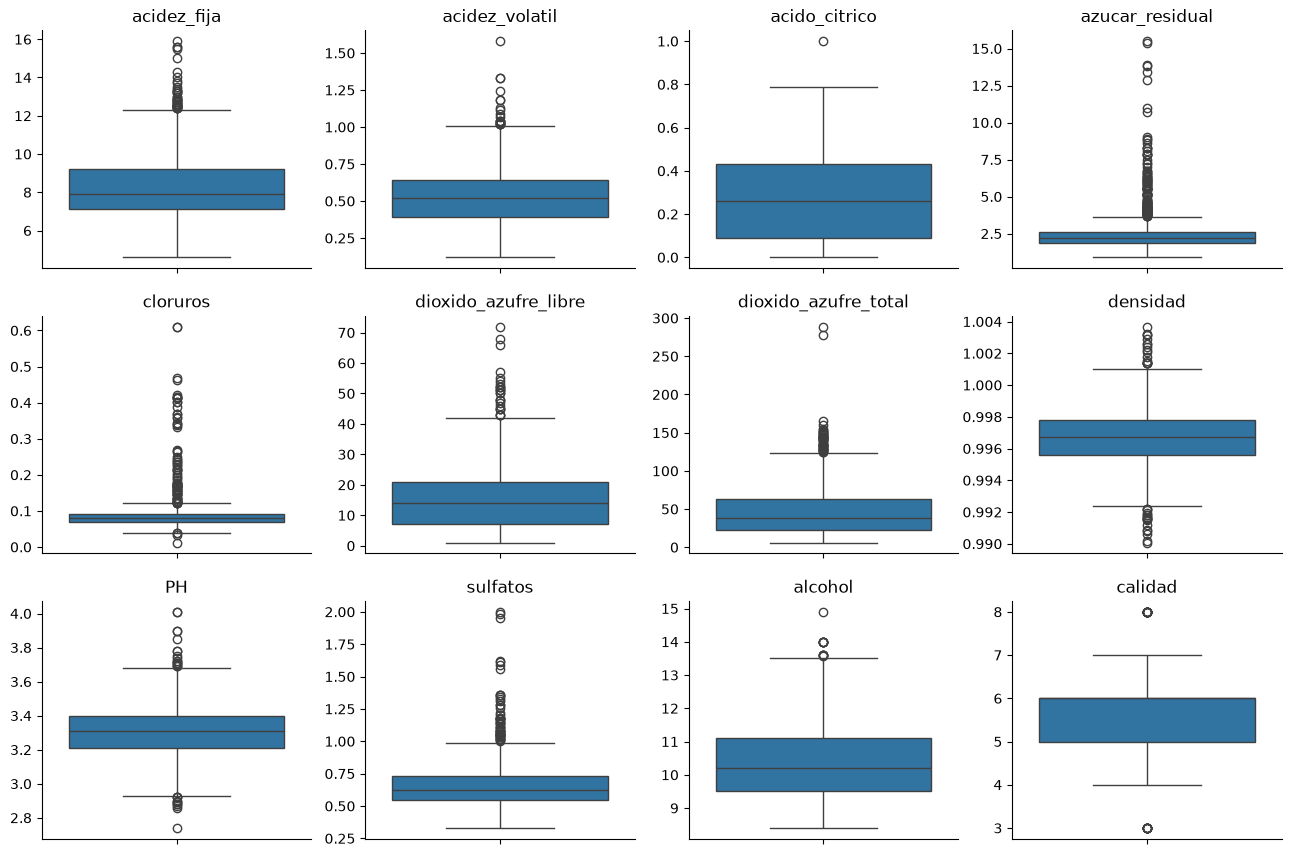

In [57]:
num_cols = wq_df.select_dtypes(include=np.number).columns
n_cols = 4                                   # boxplots por fila
n_rows = int(np.ceil(len(num_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.5 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.boxplot(y=wq_df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")

sns.despine()

In [64]:
# Creo funcion para contar la cantidad de outliers
def contar_outliers(series):
    #Aqui se realizar el calculo de cuartiles, IQR y los bigotes superior e inferior
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    li = q1 - (1.5*iqr)
    ls = q3 + (1.5*iqr)

    return ((series < li) | (series > ls)).sum()

for col in wq_df.select_dtypes(np.number).columns:
    print(f'{col:20s} outliers: {contar_outliers(wq_df[col])}')

acidez_fija          outliers: 41
acidez_volatil       outliers: 19
acido_citrico        outliers: 1
azucar_residual      outliers: 126
cloruros             outliers: 87
dioxido_azufre_libre outliers: 26
dioxido_azufre_total outliers: 45
densidad             outliers: 35
PH                   outliers: 28
sulfatos             outliers: 55
alcohol              outliers: 12
calidad              outliers: 27


Las conclusiones que puedo sacar estos valores son:
1. **Azucar Residual y Cloruros concentran la mayor cantidad**: Como se puede observan en el describe(), tanto para la feature Azucar residual como para cloruros, los valores máximo son altos tipico de vinos tintos secos y uno poco mas dulces o salinos.
2. **Dioxido de Azufre Total**: Este es un caso a analizar, ya que hay dos valores que se encuentran muy alejados; 289.00 y 278.00. En la enología, una concentraciones de SO₂ libre superiores a 50 ppm se vuelve evidente en el aroma y el sabor, por lo que se podría pensar que hay una mal carga de los datos o un error de medición.
3. **En general, no los eliminaría**. Con solo 1599 filas, sacarlos quita información. Además, los vinos de calidad extrema suelen ser los que tienen valores atípicos.